# Notebook 06 – Demo: dùng mô hình cuối để dự đoán MPG
Mô hình cuối (Voting: Ridge + Gradient Boosting, cấu hình chọn ở notebook 05) nằm trong `src/final_model.py`.
Có thể sửa thông số ở mục 2 rồi chạy lại ô đó để dự đoán xe bất kỳ. Ứng dụng có giao diện: chạy `streamlit run app/app.py` từ thư mục gốc dự án.
Chạy notebook từ thư mục `notebooks/`.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import TARGET, split
from final_model import car, train_final_model

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
train, test = split()
model = train_final_model()          # khớp trên 318 mẫu huấn luyện, khoảng 2 giây
p = model.predict(test)
print(f"Kiểm tra lại: RMSE trên tập kiểm tra = {np.sqrt(np.mean((test[TARGET] - p) ** 2)):.3f} (báo cáo: 2,314)")

Kiểm tra lại: RMSE trên tập kiểm tra = 2.314 (báo cáo: 2,314)


## 1. Dự đoán một số xe trong tập kiểm tra (mô hình chưa từng thấy các xe này khi huấn luyện)

In [2]:
mau = test.assign(du_doan=p.round(1), sai=(p - test[TARGET]).round(1)).sample(8, random_state=1)
mau[["name", "model_year", "cylinders", "horsepower", "weight", "origin", "mpg", "du_doan", "sai"]]

,name,model_year,cylinders,horsepower,weight,origin,mpg,du_doan,sai
63,datsun 210,79,4,65.0,2020,japan,31.8,35.6,3.8
27,ford pinto,74,4,80.0,2451,usa,26.0,24.1,-1.9
31,ford pinto,75,4,83.0,2639,usa,23.0,23.4,0.4
69,honda civic 1500 gl,80,4,67.0,1850,japan,44.6,35.4,-9.2
46,bmw 320i,77,4,110.0,2600,europe,21.5,24.8,3.3
47,mazda rx-4,77,3,110.0,2720,japan,21.5,21.8,0.3
53,buick century special,78,6,105.0,3380,usa,20.6,19.6,-1.0
74,buick century,81,6,110.0,3415,usa,22.4,21.3,-1.1


## 2. Dự đoán một xe nhập tay
Sửa các con số dưới đây rồi chạy lại ô. Đơn vị: dung tích inch khối, công suất mã lực, khối lượng lb, tăng tốc 0–60 mph tính bằng giây, năm 70–82.

In [3]:
xe = car(cylinders=4, displacement=120, horsepower=90, weight=2500, acceleration=16, model_year=78, origin="japan", diesel=False)
mpg = model.predict(xe)[0]
print(f"MPG dự đoán: {mpg:.1f}  (≈ {235.215 / mpg:.1f} lít/100 km)")

MPG dự đoán: 26.5  (≈ 8.9 lít/100 km)


## 3. Thử "nếu… thì…": MPG thay đổi thế nào theo khối lượng, năm sản xuất và loại nhiên liệu?
Giữ các thông số khác như xe ở mục 2, chỉ thay đổi một yếu tố. Chỉ xét trong miền dữ liệu huấn luyện để mô hình không phải ngoại suy.

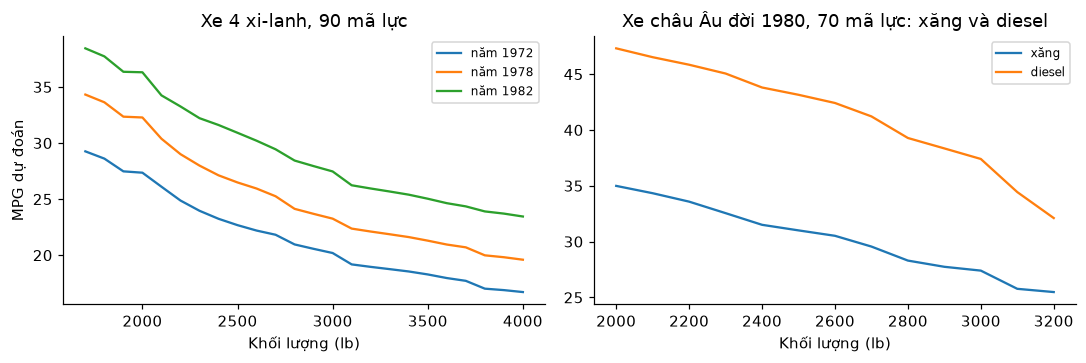

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
w = np.arange(1700, 4001, 100)
for nam in [72, 78, 82]:
    ax[0].plot(w, model.predict(pd.concat([car(4, 120, 90, x, 16, nam, "japan") for x in w])), label=f"năm 19{nam}")
ax[0].set_xlabel("Khối lượng (lb)"); ax[0].set_ylabel("MPG dự đoán"); ax[0].legend(fontsize=8)
ax[0].set_title("Xe 4 xi-lanh, 90 mã lực")
# 7 xe diesel trong tập huấn luyện chỉ nặng 1985–3230 lb, công suất 48–85 mã lực: chỉ so sánh trong vùng này
wd = np.arange(2000, 3201, 100)
for d, ten in [(False, "xăng"), (True, "diesel")]:
    ax[1].plot(wd, model.predict(pd.concat([car(4, 120, 70, x, 18, 80, "europe", diesel=d) for x in wd])), label=ten)
ax[1].set_xlabel("Khối lượng (lb)"); ax[1].legend(fontsize=8); ax[1].set_title("Xe châu Âu đời 1980, 70 mã lực: xăng và diesel")
plt.tight_layout(); plt.show()

**Nhận xét.** Với xe 4 xi-lanh 90 mã lực, MPG dự đoán giảm khi xe nặng hơn (đời 1978: 32,4 ở 1900 lb, 23,3 ở 3000 lb, 19,6 ở 4000 lb) và tăng theo năm sản xuất (ở 2500 lb: 22,7 năm 1972, 26,5 năm 1978, 30,9 năm 1982), đúng với khảo sát dữ liệu (mục 2.2.3) và mức ảnh hưởng đặc trưng (mục 3.4.4). Ở cùng khối lượng, xe diesel được dự đoán tiết kiệm hơn xe xăng 7–12 MPG (ví dụ 2500 lb: 43,2 so với 31,0), cùng cỡ với các xe diesel thật trong dữ liệu (vw rabbit diesel 43–44 MPG ở khoảng 2000 lb).

**Giới hạn cần nói rõ khi demo:** tập huấn luyện chỉ có 7 xe diesel, nặng 1985–3230 lb, công suất 48–85 mã lực. Ra ngoài vùng này, các số hạng tương tác bậc 3 của Ridge ngoại suy rất kém: xe diesel 90 mã lực được dự đoán 57,0 MPG ở 1700 lb nhưng chỉ 21,5 MPG ở 3800 lb, thấp hơn cả xe xăng cùng cỡ (23,0). Vì vậy biểu đồ bên phải chỉ vẽ trong vùng có dữ liệu, và ứng dụng Streamlit (`app/app.py`) cảnh báo khi thông số nằm ngoài miền dữ liệu huấn luyện.

## 4. Thao tác nhanh khi vấn đáp
Ví dụ đổi số láng giềng của KNN hoặc hệ số α của Ridge rồi chạy lại CV 5-fold trên tập huấn luyện (cùng fold với notebook 03).

In [5]:
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from preprocess import build_preprocessor
from data import NUM, CAT
from evaluate import cv_folds, cv_score

folds = cv_folds(train)
POLY = ["weight", "horsepower", "acceleration", "model_year"]
for ten, m, X in [("KNN k = 5", make_pipeline(build_preprocessor(), KNeighborsRegressor(n_neighbors=5)), train[NUM + CAT]),
                  ("Ridge bậc 6, α = 1", make_pipeline(build_preprocessor(POLY, CAT, degree=6), Ridge(alpha=1)), train[POLY + CAT])]:
    s = cv_score(m, X, train[TARGET], folds)
    print(f"{ten}: RMSE CV {s['RMSE_cv']:.2f} ± {s['RMSE_cv_std']:.2f}, R² {s['R2_cv']:.3f}")

KNN k = 5: RMSE CV 3.14 ± 0.50, R² 0.837
Ridge bậc 6, α = 1: RMSE CV 2.85 ± 0.37, R² 0.867
